![KAUST Academy](https://i.imgur.com/a3uAqnb.png)

# Day 40 -- Lab 1: Icons to Words

In a party game nobody may speak: one player picks a secret word and gives a clue only by pointing, in order, at small icons that both players can see. You write the other player, the guesser: for every game it receives the clue and a list of 100 options that holds the secret, and it answers with 10 guesses, best first. Your file is scored per game: 0.9 when the secret is among your ten guesses, plus a little more the earlier it comes.

**Your role:** Fill in the `# Your code here` cells in order. Run every cell, including the ones already written for you.

**Dataset:** Real games of this party game, 178 in all: 60 come with their secret word and 118 are the test, whose secrets only the scorer holds. The setup cell leaves in `DATA_DIR`: `train.csv` (`id`, `hints`: the icon ids of the clue in order, separated by spaces, `options`: the 100 options separated by spaces, `label`: the secret), `test.csv` (the same columns without `label`), `icons.csv` (`icon_id`, `description`: what the icon can mean, its meanings separated by ` / `), the folder `icons/` with the picture of every icon (`icon_007.png` is icon 7) and `sample_submission.csv` (the format of the file you hand in). A word of two words is written with `_`: `light_bulb`.

Your work is checked as you go, and the clock started at the opening time, so start at once and run every checkpoint cell.

---
# Setup

Run the four cells below in order. The first one installs the checkpoint library where it is missing. The second one opens your session with the scorer: replace `PASTE-YOUR-ID` by your own student id before you run it. From that cell on, this notebook records cell runs, cell source and errors for assessment. The third one imports the libraries and the fourth one gets the data.

Your id is yours alone. Do not share a copy of this notebook that holds it.

In [2]:
# Installs the checkpoint library where it is missing. On Colab that takes a few seconds.
import importlib.util

if importlib.util.find_spec("olympiad") is None:
    !pip -q install olympiad-lab sentence-transformers
    importlib.invalidate_caches()


In [3]:
import os
from olympiad import ck

STUDENT_ID = os.environ.get("OLYMPIAD_STUDENT_ID", "S14-6WXC")
ck.start(lab="uns-01", student_id=STUDENT_ID)


Session open. Minute 14. Lab: Icons to Words.
This lab records cell runs, cell source and errors for assessment.
Parts 0 of 7: LOAD - | LOOK - | SPLIT - | BATCH - | MODEL - | EVAL - | SUBMIT -

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print("libraries ready")


libraries ready


In [5]:
import os

DATA_DIR = os.environ.get("OLYMPIAD_DATA_DIR")      # set when the instructor runs the notebook again
if not DATA_DIR:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("sattamjaltwaim/icons-to-words")
print("Data folder:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR))[:20])


Using Colab cache for faster access to the 'icons-to-words' dataset.
Data folder: /kaggle/input/icons-to-words
['icons', 'icons.csv', 'sample_submission.csv', 'test.csv', 'train.csv']


---
# The task

**The game.** Two players share a board of 118 icons, and every icon has a short description of what it can
mean (`Fire / Burn / Cooking`). The clue-giver picks a secret word or phrase and gives a clue by pointing at
an **ordered** list of icons; speaking and writing are not allowed. The order means something: the first icon
is usually the core idea of the secret, and the icons after it give context that makes it clear. For example,
*a job* then *fire* then *protection* could be a firefighter.

**Your program** is the guesser. For every game it gets the clue (the icon ids, in order) and a list of 100
options; the secret is always one of them. It answers with a list of **10 guesses**, the most likely first.

**The score of a game** is computed by the scorer cell in Part 2. The score of your file is the mean over the
test games.

**The rules.** Any model with fewer than 1 billion parameters; the organisers' starter uses the sentence model
`all-MiniLM-L6-v2` (22 million parameters). No external model service (no chatbot, no online API) gives the
answers. Your notebook must run from start to end.

**The file you hand in** has one row per test game: its `id`, and `guesses`, the ten words separated by
spaces, the most likely first, written exactly as in the options.

**The starter.** The starter solution takes the statement at its word: it ranks the 100 options by their
similarity to the description of the **first icon** of the clue, the core idea, with `all-MiniLM-L6-v2`. The
score of its file is the **baseline**; your points count from there upward.

**Today you work alone.** Nobody helps with the code and AI assistants are off. This morning's slides are yours
to use.


---
# The starter solution

Every olympiad task comes with a starter solution: a short notebook that reads the files and hands in a valid file. Its score is the **baseline**, and your points count up from it. This is the starter of this task. Read it before you begin; you may reuse any of its lines.

```python
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
icons = pd.read_csv(os.path.join(DATA_DIR, "icons.csv"))
description = dict(zip(icons["icon_id"], icons["description"]))
model = SentenceTransformer("all-MiniLM-L6-v2")


def guess(hints, options):
    """The first icon is the core idea of the secret: the options most similar to it come first."""
    core = model.encode(description[int(hints.split()[0])], normalize_embeddings=True)
    options = options.split()
    vectors = model.encode([w.replace("_", " ") for w in options], normalize_embeddings=True)
    return [options[i] for i in np.argsort(-(vectors @ core))[:10]]


submission = pd.DataFrame({"id": test["id"],
                           "guesses": [" ".join(guess(h, o)) for h, o in zip(test["hints"], test["options"])]})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
```

---
# Part 1 -- Load and look

Every task begins the same way: get the files into memory, then look at the data before you build anything.

## Task 1: Load the files

Read the four CSV files of `DATA_DIR` into `train`, `test`, `icons` and `sample`. Print the shape of each.

(60, 4)
(118, 3)
(118, 2)
(118, 2)


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [7]:
ck.load(train=train, test=test, sample=sample, icons=icons)


✓ LOAD: Your data is loaded and has the expected size.
Parts 1 of 7: LOAD ✓ | LOOK - | SPLIT - | BATCH - | MODEL - | EVAL - | SUBMIT -

## Task 2: Look at one game

Store the first five rows of `train` in `first_rows` and its number of rows in `n_rows`. Make `description`, a dictionary from an icon id (a whole number) to its description. Then print, for the first game of `train`, every icon id of its clue next to its description, then its secret and the number of its options.

In [13]:
first_rows = train.head()
n_rows =len(train)
description = {}

First game clue:
Icon   0: Object / Box
Icon  35: Attack / Conflict - Combat / Weapon
Icon  66: Metal
Icon  71: Cut - Break / Separation / Half
Icon  99: Thin - Fine / Narrow / Short

Secret: sword
Number of options: 100


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [14]:
ck.look(first_rows, size=n_rows)


,id,hints,options,label
0,0,0 35 66 71 99,boar sunglasses monocle pig palace polar_bear ...,sword
1,1,0 53 25,pillow scented_bracelet case cup shoes scented...,perfume
2,2,5 91 97 116 104,dam space_station trash_can circus fire_exting...,ping-pong
3,3,6 63 97 32 16 57,mosquito squirrel parachute magician station m...,koala
4,4,3 37 44 117,xylophone police_officer banana porch spiderwe...,ghost


Size of the data: 60


✓ LOOK: A sample is shown and the size of the data is right.
Parts 2 of 7: LOAD ✓ | LOOK ✓ | SPLIT - | BATCH - | MODEL - | EVAL - | SUBMIT -

Run this cell to see two clues the way the players see them.

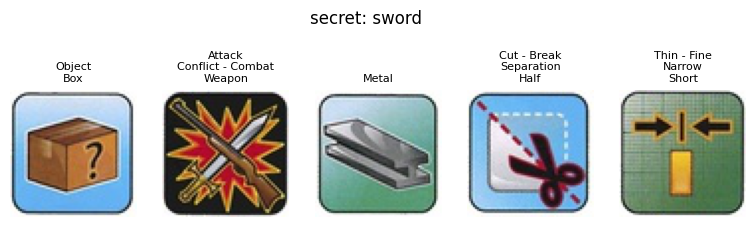

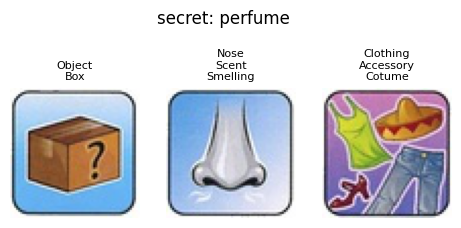

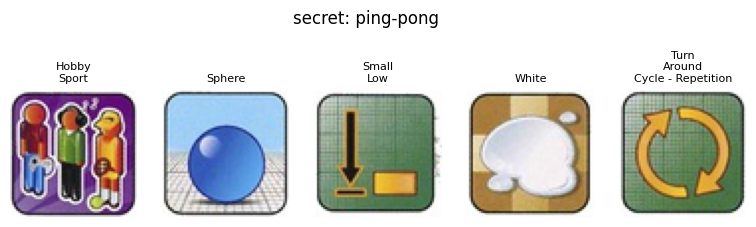

In [16]:
from PIL import Image


def show_clue(row):
    """The icons of one clue, in order, as the players see them."""
    hints = [int(h) for h in row["hints"].split()]
    meaning = dict(zip(icons["icon_id"], icons["description"]))
    fig, axes = plt.subplots(1, len(hints), figsize=(1.9 * len(hints), 2.3))
    for ax, icon in zip(np.atleast_1d(axes), hints):
        ax.imshow(Image.open(os.path.join(DATA_DIR, "icons", f"icon_{icon:03d}.png")))
        ax.set_title(meaning[icon].replace(" / ", "\n"), fontsize=8)
        ax.axis("off")
    plt.suptitle("secret: " + str(row.get("label", "?")), y=1.12)
    plt.show()


show_clue(train.iloc[0])
show_clue(train.iloc[1])
show_clue(train.iloc[2])

---
# Part 2 -- Read the task

Before any model comes the task reading: what the metric is, what two answers without a model would score, what the metric rewards, which format the file must have and what you noticed about the task. It is sent by the cell after Task 7. It earns full credit if it arrives by minute 25; after that it earns less, down to nothing at the end of the lab. It is scored after the lab, so no tick appears.

The scorer of this task, as the organisers wrote it. Run the cell; you will use `score` and `mean_score` all afternoon.

In [17]:
import math


def score(guesses, secret):
    """The score of one game: the first ten guesses count."""
    guesses = list(guesses)[:10]
    if secret not in guesses:
        return 0.0
    place = guesses.index(secret) + 1
    return 0.9 + 0.1 / math.log2(place + 1)


def mean_score(all_guesses, secrets):
    """The score of a file: the mean over its games."""
    return float(np.mean([score(g, s) for g, s in zip(all_guesses, secrets)]))


print(score(["cat", "dog", "cactus"], "cactus"), score(["cat", "dog"], "cactus"))


0.9500000000000001 0.0


## Task 3: What the scorer gives one game

The cell above is the scorer of one game. Which sentence says what it gives?

- **a** 1 when the first guess is the secret, and 0 otherwise.
- **b** 0.9 when the secret is anywhere among the first ten guesses, plus 0.1 / log2(place + 1): 1.0 at place 1, about 0.93 at place 10, and 0 when the secret is not in the ten.
- **c** 1 / place of the secret among all 100 options, whatever the place.

Store the letter in `formula`.

In [18]:
formula = 'b'

## Task 4: Two answers without a model

What would two answers that need no model score? `first_ten` guesses, in every game, the first ten options in the order they are listed; `last_ten` guesses the last ten, the very last one first. Score both on the games of `train` with `mean_score` and store the two numbers in the dictionary `trivial` under these two names.

In [22]:
option_list = [opt.split() for opt in train['options']]
first_ten = [option[:10] for option in option_list]
last_ten = [option[-1:-11:-1] for option in option_list]
score_first = mean_score(first_ten, train['label'])
score_last = mean_score(last_ten, train['label'])

trivial = {'first_ten':score_first, 'last_ten':score_last}

## Task 5: What the metric rewards

File A puts the secret at place 10 in every game. File B puts it at place 1 in half of the games and leaves it out of the other half. What do they score?

- **a** B scores more, 0.5 against about 0.29 for A: only the first guess really counts.
- **b** A scores more, about 0.93 against 0.5 for B: 0.9 of a game's score is for having the secret anywhere in the ten, and the place only moves the last 0.1.
- **c** Both score 0.5.

Store the letter in `rewards`.

In [23]:
rewards = 'b'

## Task 6: The format of the file

Store the format rules in the dictionary `format_rules`: `n_rows`, the number of rows your file must have, `id_col`, the name of its id column, and `n_guesses`, the number of guesses in one row. Read all three from what you loaded; do not type the numbers.

{'n_rows': 118, 'id_col': 'id', 'n_guesses': 10}


## Task 7: What you noticed

Write in `facts`, in one to three sentences of your own, what you noticed about this task that its statement does not say and that could change your score.

In [26]:
facts = 'i dont know'

Run the cell to send your task reading. It answers with one line and shows no score.

In [27]:
ck.reading(formula=formula, trivial=trivial, rewards=rewards, format=format_rules, facts=facts)


Task reading received at minute 32, after minute 25: it counts for less.

---
# Part 3 -- A first file

The simplest pipeline that ends in a file comes first: aim to hand it in within the first hour, then make it better.

## Task 8: Hold out validation games

Split `train` into a part `tr` and a validation part `va` of 20 games, with `random_state=0`. Keep the ids of the two parts in `train_ids` and `val_ids`. Print the number of games in each part.

In [31]:
tr,va = train_test_split(train, test_size = 20, random_state = 0)
train_ids = tr['id']
val_ids = va['id']

Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [32]:
ck.split(train_ids=train_ids, val_ids=val_ids)


✓ SPLIT: The validation set shares no rows with the training set.
Parts 3 of 7: LOAD ✓ | LOOK ✓ | SPLIT ✓ | BATCH - | MODEL - | EVAL - | SUBMIT -

## Task 9: One text for each clue

Write `make_query(hints)`, which turns the text of a `hints` cell into one text that a sentence model can read. Build `queries_tr`, the list of the texts of the clues of `tr`, and `y_tr`, the list of their secrets. Print the first text next to its secret.

In [35]:
def make_query(hints):
  hint_ids = [int(h) for h in hints.split()]
  return " / ".join([description[h] for h in hint_ids])
queries_tr = [make_query(h) for h in tr['hints']]
y_tr = list(tr['label'])

Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [36]:
ck.batch(queries_tr, y_tr)


✓ BATCH: Batch shape, size and data type are right.
Parts 4 of 7: LOAD ✓ | LOOK ✓ | SPLIT ✓ | BATCH ✓ | MODEL - | EVAL - | SUBMIT -

## Task 10: The sentence model

Load a pretrained sentence model into `model` (the starter's model is a good first choice). Build `queries_va`, the texts of the clues of `va`. Print the shape of what the model gives for the first three of them.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Shape of the first three query embeddings: (3, 384)


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [39]:
ck.model(model, queries_va)


✓ MODEL: The model runs on one batch and its output has the right shape and data type.
Parts 5 of 7: LOAD ✓ | LOOK ✓ | SPLIT ✓ | BATCH ✓ | MODEL ✓ | EVAL - | SUBMIT -

## Task 11: Ten guesses for one game

Write `guess(hints, options)`, which takes the `hints` and `options` cells of one game and returns a list of ten options, the most likely first. Print what it gives the first game of `va`, next to that game's secret.

In [40]:
def guess(hints, options):


## Task 12: Score the validation games

Store in `val_score` the `mean_score` of your guesses for the games of `va` against their secrets: one number between 0 and 1. Print it.

In [ ]:
# Your code here


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [ ]:
ck.eval(val_score, metric="hits_ndcg")


## Task 13: Write the submission file

Write `submission.csv` in the format of `sample`: for every game of `test`, its `id` and its ten guesses in one text, separated by spaces. Leave the index out. Print its shape and its first rows.

In [ ]:
# Your code here


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [ ]:
ck.submit("submission.csv")


---
# Part 4 -- Debugging drill

A classmate tried to score the 100 options of one validation game against its clue, all at once. The cell stops with an error. Run the first cell: it starts the drill's clock. Then repair the classmate's cell until it prints the shape of `drill_similarity`, one number per option, and run the check. The clock stops at the first check that passes. Read the error message before you change anything.

In [ ]:
ck.drill_start("bug-shp-1")


## Task 14: Repair the classmate's cell

Change as little as you can: the options, the model and the matrix product stay.

In [ ]:
drill_options = va["options"].iloc[0].split()
drill_query = model.encode([queries_va[0]], normalize_embeddings=True)
drill_option_vectors = model.encode(drill_options, normalize_embeddings=True)
drill_similarity = drill_option_vectors @ drill_query
print(drill_similarity.shape)


In [ ]:
ck.drill_check("bug-shp-1", drill_similarity)


---
# Part 5 -- Challenge: your best file

Your first file is on the board. Now make it better, one change at a time. A change worth keeping comes from something you found in the data or in the rules, and it raises the score of the validation games.

## Task 15: Hand in your best file

Make at least one change to how you guess, compare it with your first file on the games of `va` with `mean_score`, and print both scores. Then write `submission.csv` again with the better way. Your last accepted file is your answer, so hand in a new file only when you expect it to be better.

In [ ]:
# Your code here


Run the checkpoint cell. It prints a tick or a cross and one sentence that says why.

In [ ]:
ck.submit("submission.csv")


---
## Task 16: Reflect

Which change moved your validation score most, and how did you find it: in the data, in the rules or by trying? Which sentence of the statement did you test against the data, and what did the data say? If you met this task again with one hour, what would you do in the first 15 minutes?

*Your answers here*

---
# Finish

Run the last cell when you are done. It sends what is still waiting and hands in this notebook.

In [ ]:
ck.finish()

---
## Conclusion

- **Read the task first**: the scorer read as code, two answers without a model, what the ten places are worth, and the format of the file, all before any model.
- **Retrieval with a sentence model**: a clue and 100 options turned into vectors, ranked by cosine similarity, ten different guesses handed in.
- **A sentence of the rules is tested, not trusted**: what the statement says about the first icon, checked against the games.
- **All of the data is data**: what the games have in common, found by counting, and used.
- **Debugging**: a shape error in a matrix product read, located and repaired against the clock.

---

Made By **Sattam Altwaim**